**UNEMPLOYMENT ANALYSIS WITH PYTHON**

IMPORT LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


UPLOAD DATASETS

In [ ]:
from google.colab import files

print("Upload your unemployment CSV dataset(s):")
print("1. Unemployment in India.csv")
print("2. Unemployment_Rate_upto_11_2020.csv")

uploaded = files.upload()

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload at least one CSV file.")

print("\nUploaded files:")
for file in csv_files:
    print(file)

Upload your unemployment CSV dataset(s):
1. Unemployment in India.csv
2. Unemployment_Rate_upto_11_2020.csv


Saving Unemployment in India.csv to Unemployment in India.csv
Saving Unemployment_Rate_upto_11_2020.csv to Unemployment_Rate_upto_11_2020.csv

Uploaded files:
Unemployment in India.csv
Unemployment_Rate_upto_11_2020.csv


LOAD AND CLEAN DATA

In [ ]:
datasets = {}

for file in csv_files:

    df = pd.read_csv(file)

    # Clean column names
    df.columns = df.columns.str.strip()

    # Clean text values
    for col in df.select_dtypes(include=["object"]).columns:
        df[col] = df[col].astype("string").str.strip()

    # Remove completely empty rows
    df = df.dropna(how="all")

    # Convert date column
    date_col = next(
        (col for col in df.columns if col.lower() == "date"),
        None
    )

    if date_col:
        df[date_col] = pd.to_datetime(
            df[date_col],
            errors="coerce",
            dayfirst=True
        )

        if date_col != "Date":
            df.rename(columns={date_col: "Date"}, inplace=True)

        df = df.dropna(subset=["Date"])

    # Convert numeric columns
    numeric_columns = [
        col for col in df.columns
        if any(
            term in col.lower()
            for term in [
                "unemployment rate",
                "employed",
                "labour participation",
                "labor participation"
            ]
        )
    ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Remove duplicate rows
    df = df.drop_duplicates().reset_index(drop=True)

    datasets[file] = df

    print(f"\nDataset loaded: {file}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Dataset loaded: Unemployment in India.csv
Rows: 740
Columns: 7

Dataset loaded: Unemployment_Rate_upto_11_2020.csv
Rows: 267
Columns: 9


EXPLORE DATASETS

In [ ]:
for name, df in datasets.items():

    print("\n" + "=" * 65)
    print("DATASET:", name)
    print("=" * 65)

    print("\nFirst five rows:")
    display(df.head())

    print("\nDataset shape:")
    print(df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nStatistical summary:")
    display(df.describe(include="all").T)

    print("\nMissing values:")
    display(
        df.isnull().sum().to_frame("Missing Values")
    )


DATASET: Unemployment in India.csv

First five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



Dataset shape:
(740, 7)

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                     string[python]
Date                                       datetime64[ns]
Frequency                                  string[python]
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                       string[python]
dtype: object

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,NaN,NaN,NaN,2019-12-12 18:36:58.378378496,2019-05-31 00:00:00,2019-08-31 00:00:00,2019-11-30 00:00:00,2020-03-31 00:00:00,2020-06-30 00:00:00,NaN
Frequency,740,1,Monthly,740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,0.0,4.6575,8.35,15.8875,76.74,10.721298
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,49420.0,1190404.5,4744178.5,11275489.5,45777509.0,8087988.429458
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,13.33,38.0625,41.16,45.505,72.57,8.111094
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


...

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74



Dataset shape:
(267, 9)

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Data types:
Region                                     string[python]
Date                                       datetime64[ns]
Frequency                                  string[python]
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                  int64
Estimated Labour Participation Rate (%)           float64
Region.1                                   string[python]
longitude                                         float64
latitude                                          float64
dtype: object

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Region,267,27,Andhra Pradesh,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,267,NaN,NaN,NaN,2020-06-16 09:15:30.337078528,2020-01-31 00:00:00,2020-03-31 00:00:00,2020-06-30 00:00:00,2020-08-31 00:00:00,2020-10-31 00:00:00,NaN
Frequency,267,1,M,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),267.0,NaN,NaN,NaN,12.236929,0.5,4.845,9.65,16.755,75.85,10.803283
Estimated Employed,267.0,NaN,NaN,NaN,13962105.722846,117542.0,2838930.5,9732417.0,21878686.0,59433759.0,13366318.359733
Estimated Labour Participation Rate (%),267.0,NaN,NaN,NaN,41.681573,16.77,37.265,40.39,44.055,69.69,7.845419
Region.1,267,5,North,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude,267.0,NaN,NaN,NaN,22.826048,10.8505,18.1124,23.6102,27.2784,33.7782,6.270731
latitude,267.0,NaN,NaN,NaN,80.532425,71.1924,76.0856,79.0193,85.2799,92.9376,5.831738



Missing values:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0


PREPARE DATA FOR ANALYSIS

In [ ]:
RATE_COL = "Estimated Unemployment Rate (%)"
EMPLOYED_COL = "Estimated Employed"
PARTICIPATION_COL = "Estimated Labour Participation Rate (%)"

analysis_frames = []

for name, df in datasets.items():

    if "Date" not in df.columns:
        print(f"Skipping {name}: Date column not found.")
        continue

    if RATE_COL not in df.columns:
        print(f"Skipping {name}: unemployment rate column not found.")
        continue

    temp = df.copy()

    # Add source dataset name
    temp["Source Dataset"] = name

    # Handle missing region information
    if "Region" not in temp.columns:
        temp["Region"] = "Unknown"

    # Create date-related columns
    temp["Year"] = temp["Date"].dt.year
    temp["Month Number"] = temp["Date"].dt.month
    temp["Month Name"] = temp["Date"].dt.month_name()
    temp["Month"] = temp["Date"].dt.to_period("M").dt.to_timestamp()

    # Ensure unemployment rate is numeric
    temp[RATE_COL] = pd.to_numeric(
        temp[RATE_COL],
        errors="coerce"
    )

    analysis_frames.append(temp)


if not analysis_frames:
    raise ValueError(
        "No usable dataset found. Check the date and unemployment rate columns."
    )


# Combine the datasets while preserving their source
data = pd.concat(
    analysis_frames,
    ignore_index=True,
    sort=False
)

# Remove invalid unemployment percentages
data = data[
    data[RATE_COL].between(0, 100)
].copy()

print("\nCombined dataset shape:", data.shape)

print("\nFirst five rows:")
display(data.head())

print("\nDate range:")
print(data["Date"].min(), "to", data["Date"].max())


Combined dataset shape: (1007, 15)

First five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Source Dataset,Year,Month Number,Month Name,Month,Region.1,longitude,latitude
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,Unemployment in India.csv,2019,5,May,2019-05-01,<NA>,NaN,NaN
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,Unemployment in India.csv,2019,6,June,2019-06-01,<NA>,NaN,NaN
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,Unemployment in India.csv,2019,7,July,2019-07-01,<NA>,NaN,NaN
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,Unemployment in India.csv,2019,8,August,2019-08-01,<NA>,NaN,NaN
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,Unemployment in India.csv,2019,9,September,2019-09-01,<NA>,NaN,NaN



Date range:
2019-05-31 00:00:00 to 2020-10-31 00:00:00


HANDLE MISSING VALUES

In [ ]:
print("\nMissing values before handling:")
display(data.isnull().sum().to_frame("Missing Values"))

# Missing unemployment rates have already been excluded.
# Fill missing region labels where necessary.
data["Region"] = data["Region"].fillna("Unknown")

print("\nMissing unemployment rates:", data[RATE_COL].isnull().sum())

print("\nData cleaning completed!")


Missing values before handling:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,267
Source Dataset,0
Year,0
Month Number,0



Missing unemployment rates: 0

Data cleaning completed!


OVERALL UNEMPLOYMENT STATISTICS

In [ ]:
print("\nOverall Unemployment Statistics")

print(
    "Average unemployment rate:",
    round(data[RATE_COL].mean(), 2), "%"
)

print(
    "Median unemployment rate:",
    round(data[RATE_COL].median(), 2), "%"
)

print(
    "Maximum unemployment rate:",
    round(data[RATE_COL].max(), 2), "%"
)

print(
    "Minimum unemployment rate:",
    round(data[RATE_COL].min(), 2), "%"
)

print(
    "Standard deviation:",
    round(data[RATE_COL].std(), 2)
)

print("\nDetailed summary:")
display(data[RATE_COL].describe())


Overall Unemployment Statistics
Average unemployment rate: 11.91 %
Median unemployment rate: 8.89 %
Maximum unemployment rate: 76.74 %
Minimum unemployment rate: 0.0 %
Standard deviation: 10.74

Detailed summary:


,Estimated Unemployment Rate (%)
count,1007.000000
mean,11.906991
std,10.739549
min,0.000000
25%,4.685000
50%,8.890000
75%,16.125000
max,76.740000


UNEMPLOYMENT RATE DISTRIBUTION

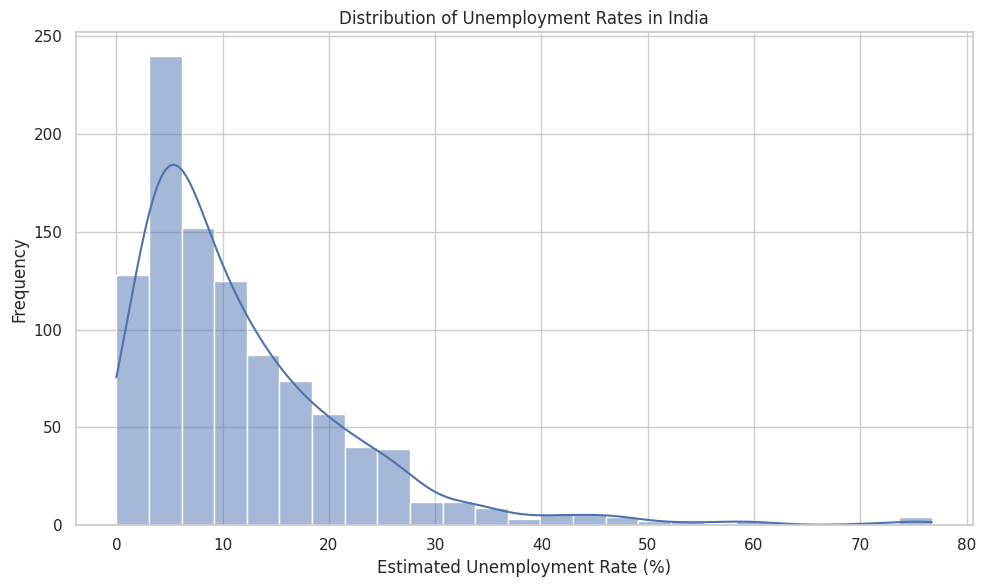

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x=RATE_COL,
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rates in India")
plt.xlabel("Estimated Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

BOXPLOT OF UNEMPLOYMENT RATES

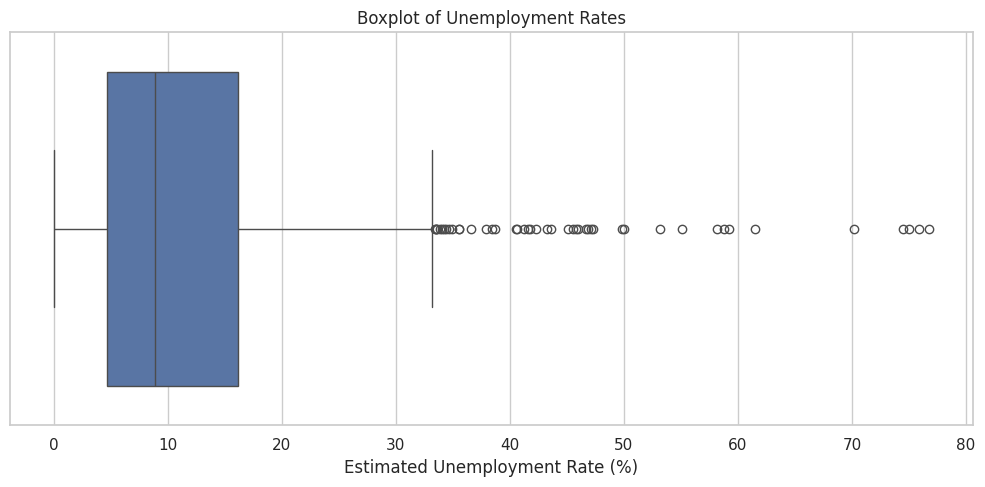

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=data,
    x=RATE_COL
)

plt.title("Boxplot of Unemployment Rates")
plt.xlabel("Estimated Unemployment Rate (%)")

plt.tight_layout()
plt.show()


 MONTHLY UNEMPLOYMENT TREND

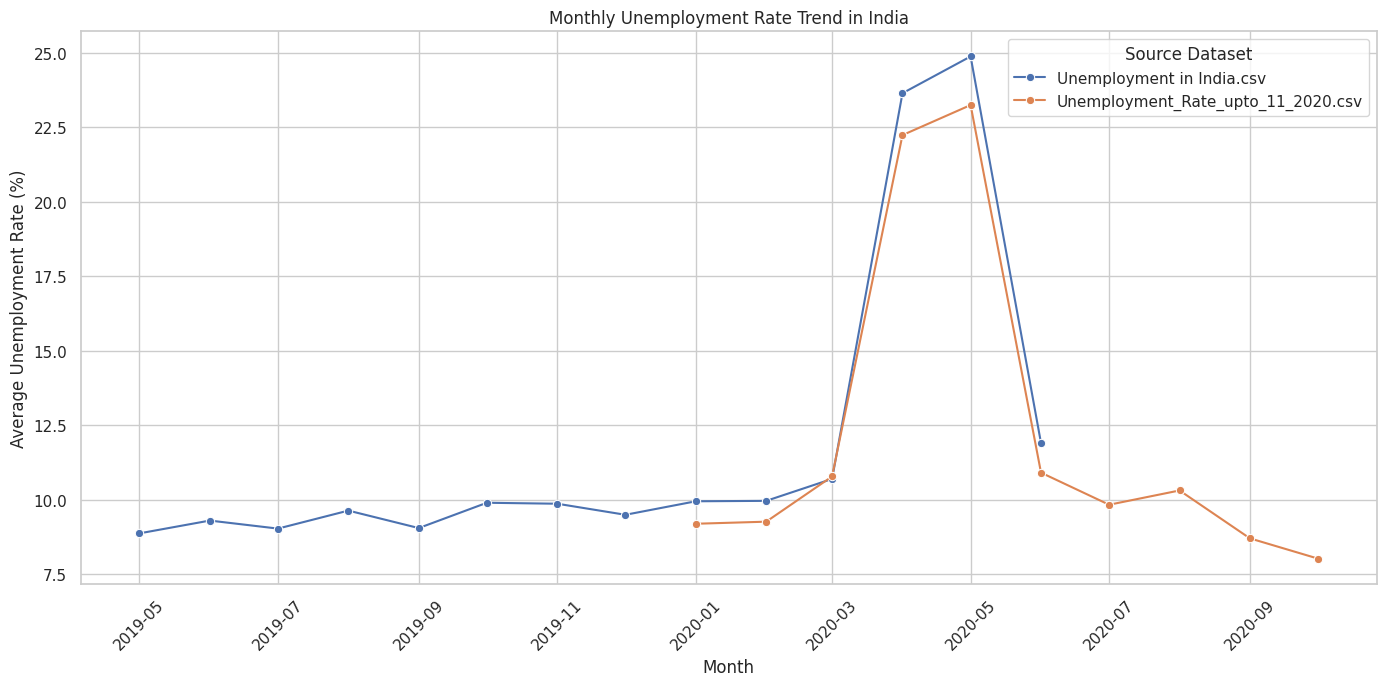

In [ ]:
monthly_trend = (
    data.groupby(
        ["Source Dataset", "Month"],
        as_index=False
    )[RATE_COL]
    .mean()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_trend,
    x="Month",
    y=RATE_COL,
    hue="Source Dataset",
    marker="o"
)

plt.title("Monthly Unemployment Rate Trend in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

YEARLY UNEMPLOYMENT TREND


Yearly unemployment rates:


,Source Dataset,Year,Estimated Unemployment Rate (%)
0,Unemployment in India.csv,2019,9.399047
1,Unemployment in India.csv,2020,15.101581
2,Unemployment_Rate_upto_11_2020.csv,2020,12.236929


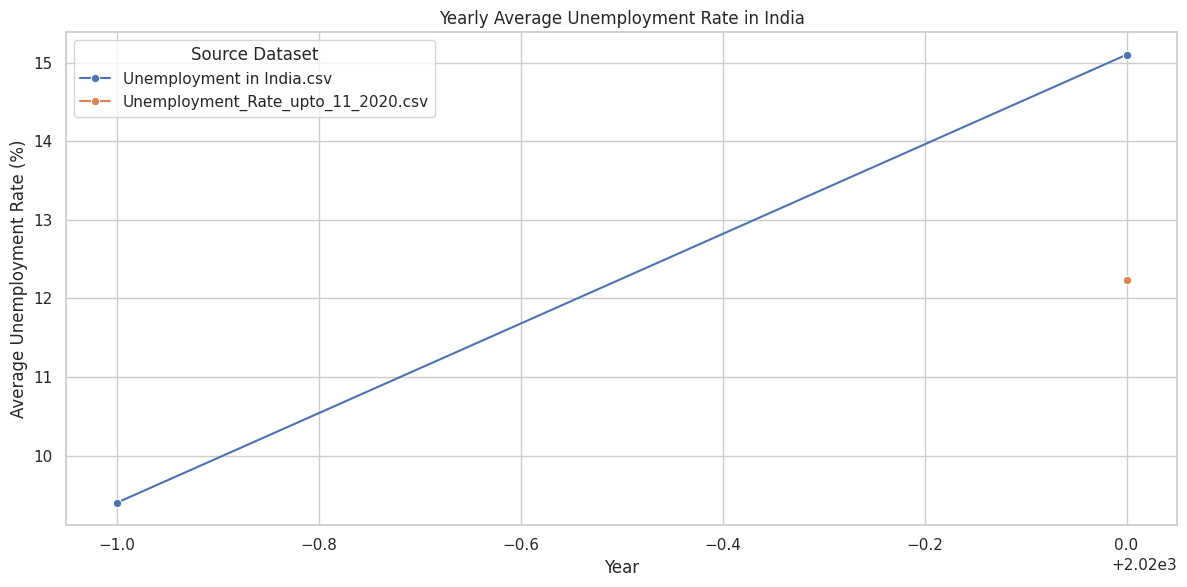

In [ ]:
yearly_trend = (
    data.groupby(
        ["Source Dataset", "Year"],
        as_index=False
    )[RATE_COL]
    .mean()
)

print("\nYearly unemployment rates:")
display(yearly_trend)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_trend,
    x="Year",
    y=RATE_COL,
    hue="Source Dataset",
    marker="o"
)

plt.title("Yearly Average Unemployment Rate in India")
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

COVID-19 IMPACT ANALYSIS


COVID-19 Period Comparison:


,Source Dataset,COVID Period,Average Rate,Median Rate,Number of Records
0,Unemployment in India.csv,Before March 2020,9.509534,7.115,536
1,Unemployment in India.csv,March 2020 Onward,17.774363,14.520,204
2,Unemployment_Rate_upto_11_2020.csv,Before March 2020,9.231346,6.660,52
3,Unemployment_Rate_upto_11_2020.csv,March 2020 Onward,12.963860,10.110,215


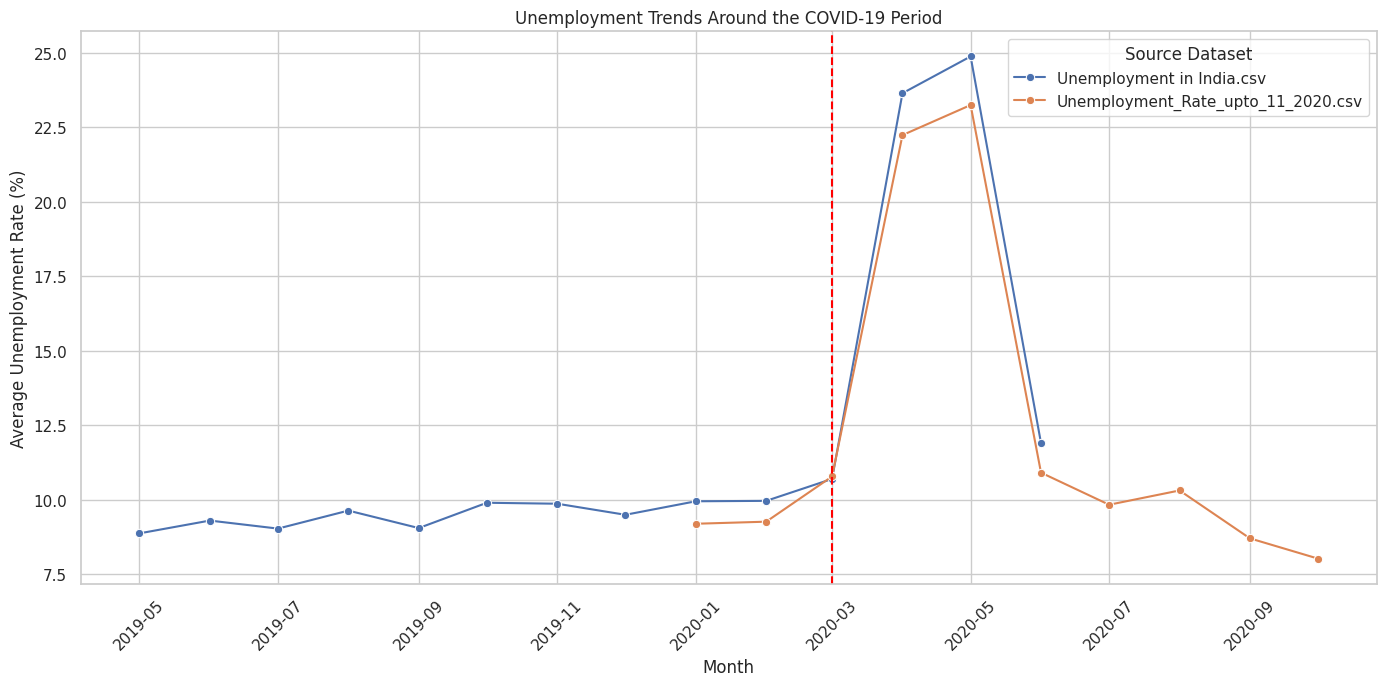

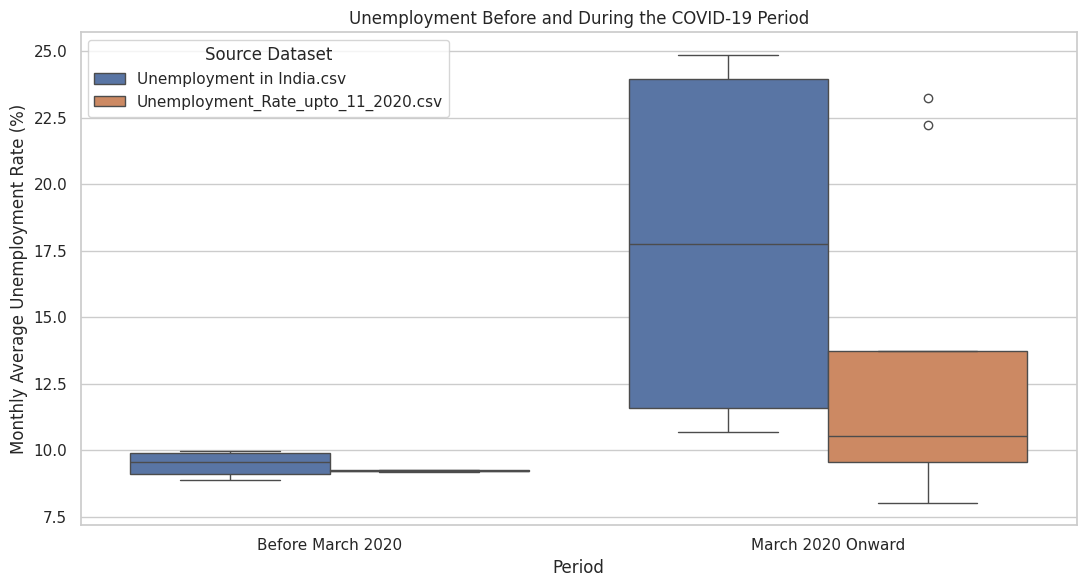

In [ ]:
# Define the comparison periods
data["COVID Period"] = np.where(
    data["Date"] < pd.Timestamp("2020-03-01"),
    "Before March 2020",
    "March 2020 Onward"
)

# Compare the periods using data up to December 2020
covid_data = data[
    data["Date"] < pd.Timestamp("2021-01-01")
].copy()

covid_summary = (
    covid_data.groupby(
        ["Source Dataset", "COVID Period"]
    )[RATE_COL]
    .agg(["mean", "median", "count"])
    .reset_index()
)

covid_summary = covid_summary.rename(
    columns={
        "mean": "Average Rate",
        "median": "Median Rate",
        "count": "Number of Records"
    }
)

print("\nCOVID-19 Period Comparison:")
display(covid_summary)


# Plot monthly trends around March 2020
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_trend,
    x="Month",
    y=RATE_COL,
    hue="Source Dataset",
    marker="o"
)

plt.axvline(
    pd.Timestamp("2020-03-01"),
    color="red",
    linestyle="--",
    label="March 2020"
)

plt.title("Unemployment Trends Around the COVID-19 Period")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# Compare monthly averages before and after March 2020
covid_monthly = monthly_trend[
    monthly_trend["Month"] <= pd.Timestamp("2020-12-01")
].copy()

covid_monthly["COVID Period"] = np.where(
    covid_monthly["Month"] < pd.Timestamp("2020-03-01"),
    "Before March 2020",
    "March 2020 Onward"
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=covid_monthly,
    x="COVID Period",
    y=RATE_COL,
    hue="Source Dataset"
)

plt.title("Unemployment Before and During the COVID-19 Period")
plt.xlabel("Period")
plt.ylabel("Monthly Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()


STATE AND REGION ANALYSIS


Regional unemployment summary:


,Source Dataset,Region,Estimated Unemployment Rate (%)
24,Unemployment in India.csv,Tripura,28.350357
35,Unemployment_Rate_upto_11_2020.csv,Haryana,27.477000
8,Unemployment in India.csv,Haryana,26.283214
51,Unemployment_Rate_upto_11_2020.csv,Tripura,25.055000
11,Unemployment in India.csv,Jharkhand,20.585000
38,Unemployment_Rate_upto_11_2020.csv,Jharkhand,19.539000
30,Unemployment_Rate_upto_11_2020.csv,Bihar,19.471000
2,Unemployment in India.csv,Bihar,18.918214
9,Unemployment in India.csv,Himachal Pradesh,18.540357
32,Unemployment_Rate_upto_11_2020.csv,Delhi,18.414000


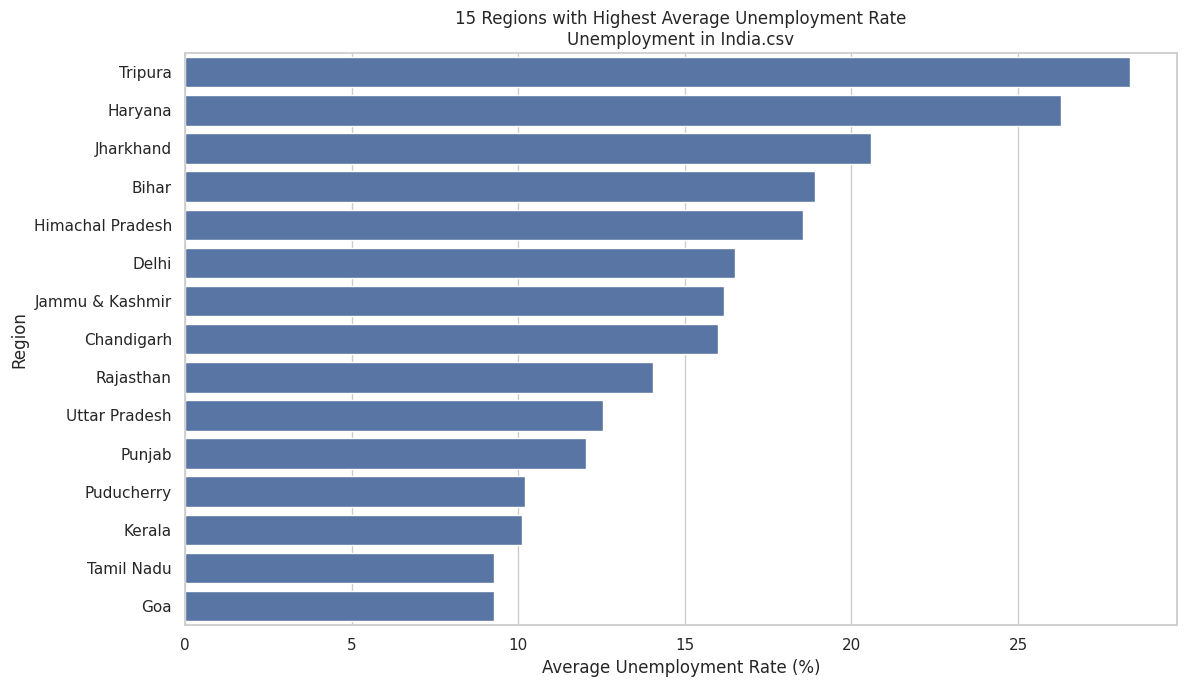

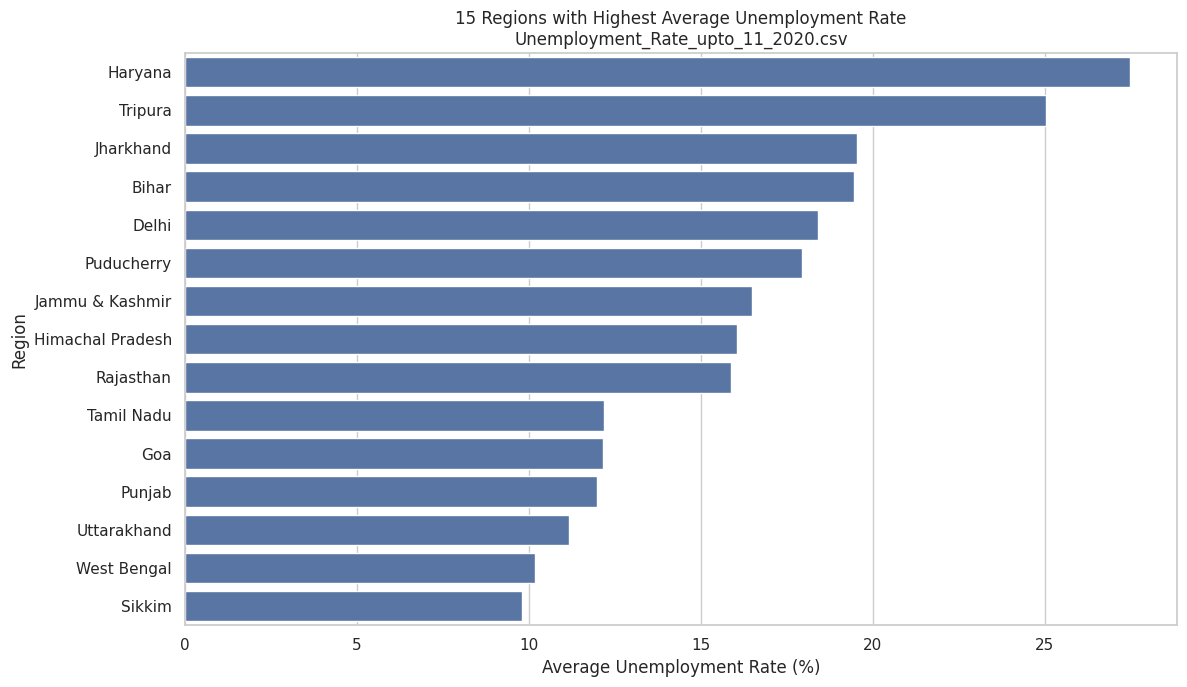

In [ ]:
region_summary = (
    data.groupby(
        ["Source Dataset", "Region"],
        as_index=False
    )[RATE_COL]
    .mean()
    .sort_values(RATE_COL, ascending=False)
)

print("\nRegional unemployment summary:")
display(region_summary)


# Highest unemployment regions
for source in region_summary["Source Dataset"].unique():

    regional_subset = region_summary[
        region_summary["Source Dataset"] == source
    ].sort_values(
        RATE_COL,
        ascending=False
    ).head(15)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=regional_subset,
        x=RATE_COL,
        y="Region"
    )

    plt.title(
        f"15 Regions with Highest Average Unemployment Rate\n{source}"
    )

    plt.xlabel("Average Unemployment Rate (%)")
    plt.ylabel("Region")

    plt.tight_layout()
    plt.show()


REGIONS WITH THE LOWEST UNEMPLOYMENT RATES

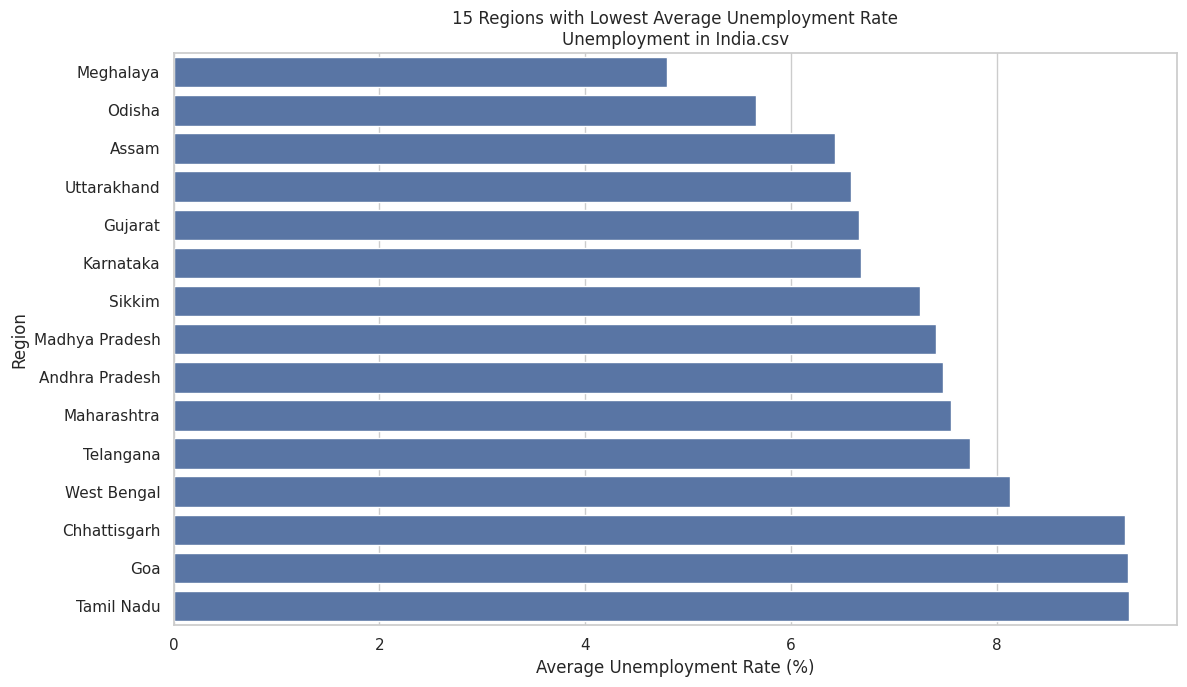

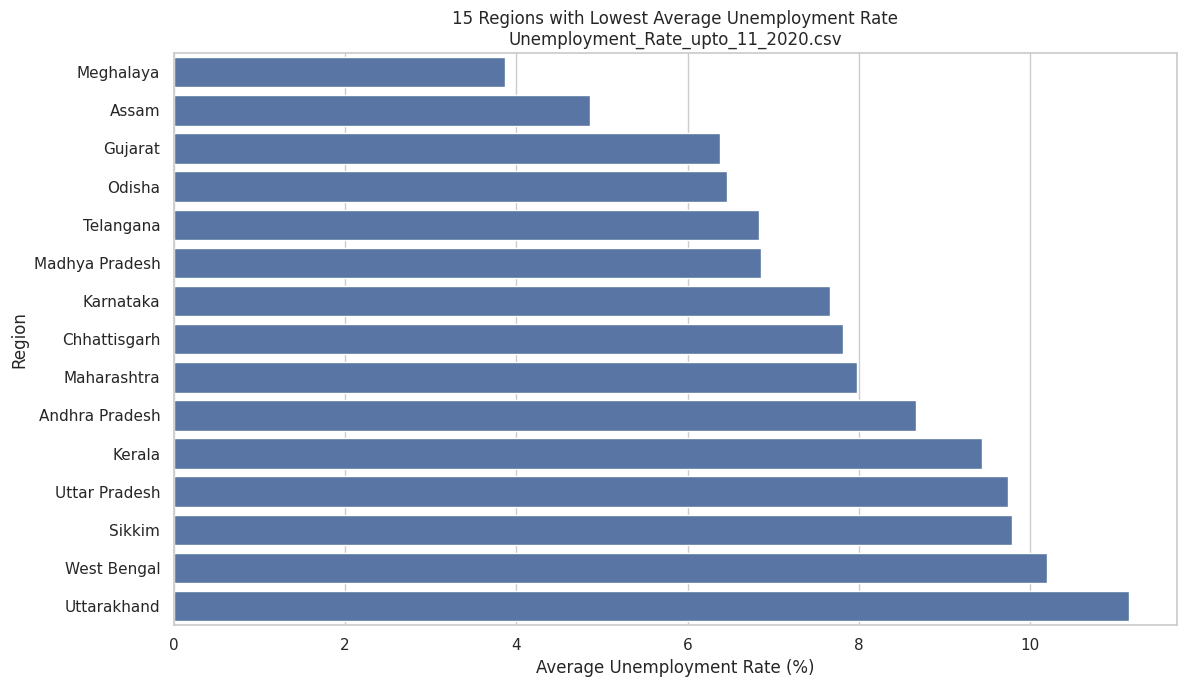

In [ ]:
for source in region_summary["Source Dataset"].unique():

    lowest_regions = region_summary[
        region_summary["Source Dataset"] == source
    ].sort_values(
        RATE_COL,
        ascending=True
    ).head(15)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=lowest_regions,
        x=RATE_COL,
        y="Region"
    )

    plt.title(
        f"15 Regions with Lowest Average Unemployment Rate\n{source}"
    )

    plt.xlabel("Average Unemployment Rate (%)")
    plt.ylabel("Region")

    plt.tight_layout()
    plt.show()

 RURAL AND URBAN UNEMPLOYMENT ANALYSIS


Unemployment by area:


,Source Dataset,Area,Estimated Unemployment Rate (%)
0,Unemployment in India.csv,Rural,10.324791
1,Unemployment in India.csv,Urban,13.166614


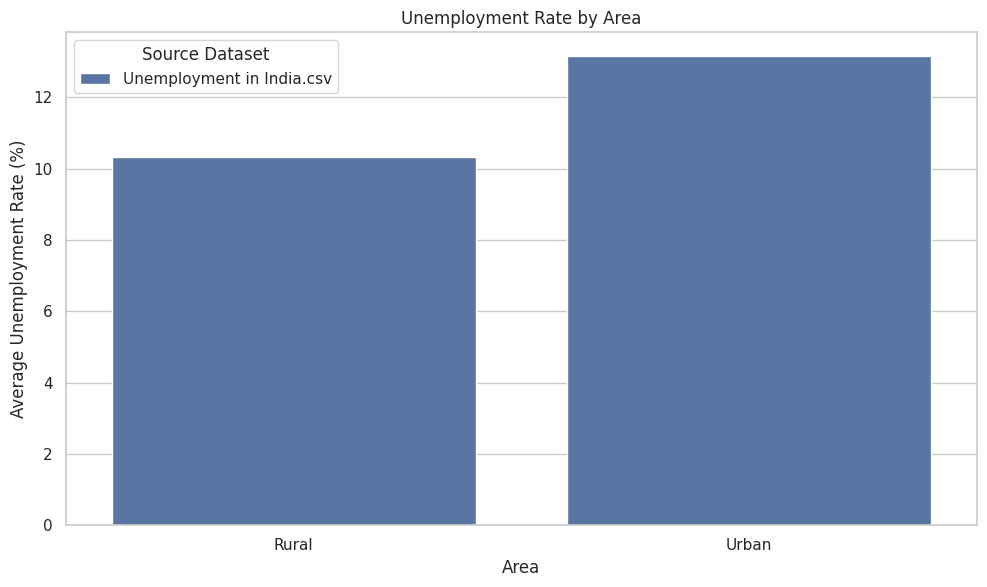

In [ ]:
area_col = next(
    (
        col for col in data.columns
        if col.lower() == "area"
    ),
    None
)

if area_col:

    area_summary = (
        data.groupby(
            ["Source Dataset", area_col],
            as_index=False
        )[RATE_COL]
        .mean()
    )

    print("\nUnemployment by area:")
    display(area_summary)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=area_summary,
        x=area_col,
        y=RATE_COL,
        hue="Source Dataset"
    )

    plt.title("Unemployment Rate by Area")
    plt.xlabel("Area")
    plt.ylabel("Average Unemployment Rate (%)")

    plt.tight_layout()
    plt.show()

else:

    print(
        "No Area column found. "
        "Skipping rural and urban comparison."
    )

SEASONAL AND MONTHLY PATTERN ANALYSIS


Average unemployment rate by calendar month:


,Source Dataset,Month Number,Month Name,Estimated Unemployment Rate (%)
0,Unemployment in India.csv,1,January,9.950755
1,Unemployment in India.csv,2,February,9.964717
2,Unemployment in India.csv,3,March,10.700577
3,Unemployment in India.csv,4,April,23.641569
4,Unemployment in India.csv,5,May,16.646190
5,Unemployment in India.csv,6,June,10.553462
6,Unemployment in India.csv,7,July,9.033889
7,Unemployment in India.csv,8,August,9.637925
8,Unemployment in India.csv,9,September,9.051731
9,Unemployment in India.csv,10,October,9.900909


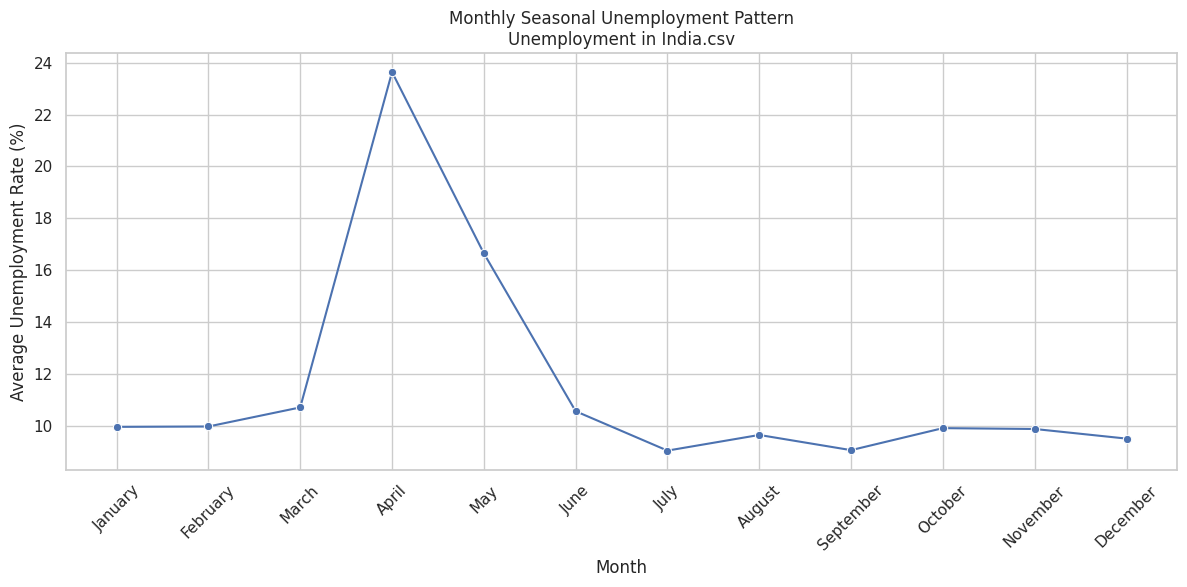

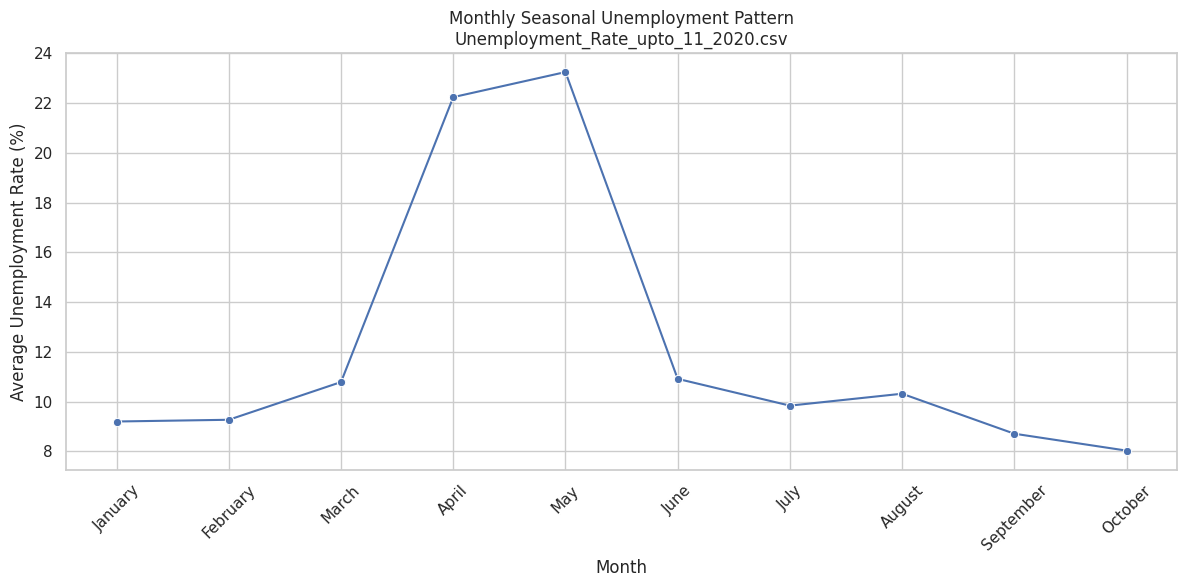

In [ ]:
seasonal_summary = (
    data.groupby(
        ["Source Dataset", "Month Number", "Month Name"],
        as_index=False
    )[RATE_COL]
    .mean()
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

seasonal_summary["Month Name"] = pd.Categorical(
    seasonal_summary["Month Name"],
    categories=month_order,
    ordered=True
)

seasonal_summary = seasonal_summary.sort_values(
    ["Source Dataset", "Month Number"]
)

print("\nAverage unemployment rate by calendar month:")
display(seasonal_summary)


for source in seasonal_summary["Source Dataset"].unique():

    subset = seasonal_summary[
        seasonal_summary["Source Dataset"] == source
    ]

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=subset,
        x="Month Name",
        y=RATE_COL,
        marker="o"
    )

    plt.title(
        f"Monthly Seasonal Unemployment Pattern\n{source}"
    )

    plt.xlabel("Month")
    plt.ylabel("Average Unemployment Rate (%)")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

LABOUR PARTICIPATION RATE ANALYSIS

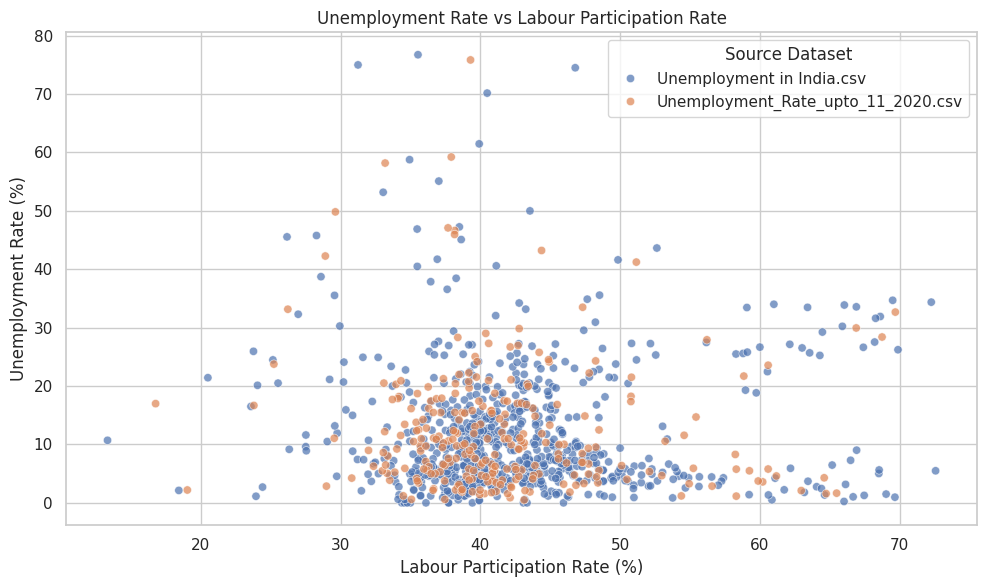


Correlation by dataset:
Unemployment in India.csv : 0.003
Unemployment_Rate_upto_11_2020.csv : -0.074


In [ ]:
if PARTICIPATION_COL in data.columns:

    data[PARTICIPATION_COL] = pd.to_numeric(
        data[PARTICIPATION_COL],
        errors="coerce"
    )

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=data,
        x=PARTICIPATION_COL,
        y=RATE_COL,
        hue="Source Dataset",
        alpha=0.7
    )

    plt.title(
        "Unemployment Rate vs Labour Participation Rate"
    )

    plt.xlabel("Labour Participation Rate (%)")
    plt.ylabel("Unemployment Rate (%)")

    plt.tight_layout()
    plt.show()

    print("\nCorrelation by dataset:")

    for source, subset in data.groupby("Source Dataset"):

        correlation = subset[
            [RATE_COL, PARTICIPATION_COL]
        ].corr().iloc[0, 1]

        print(
            source,
            ":",
            round(correlation, 3)
            if pd.notna(correlation)
            else "Not available"
        )

else:

    print("Labour participation column not found.")

EMPLOYMENT TREND ANALYSIS

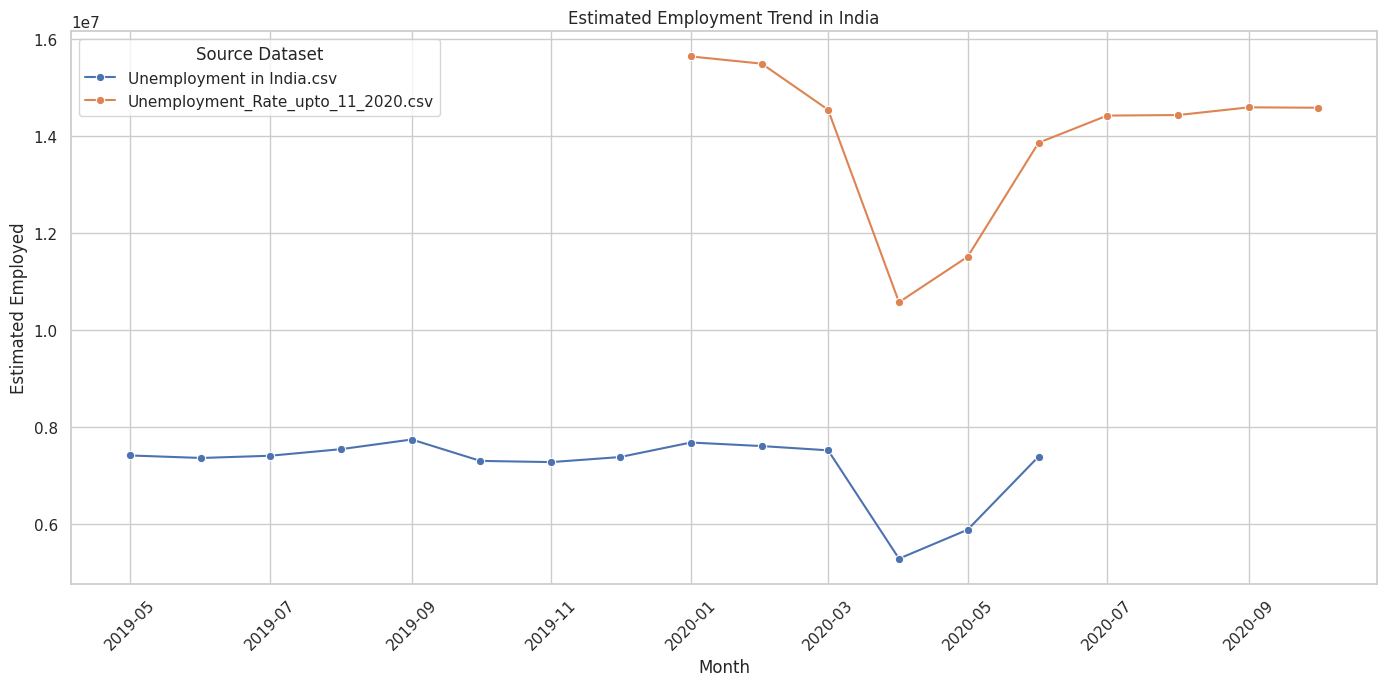

In [ ]:
if EMPLOYED_COL in data.columns:

    data[EMPLOYED_COL] = pd.to_numeric(
        data[EMPLOYED_COL],
        errors="coerce"
    )

    employment_trend = (
        data.groupby(
            ["Source Dataset", "Month"],
            as_index=False
        )[EMPLOYED_COL]
        .mean()
    )

    plt.figure(figsize=(14, 7))

    sns.lineplot(
        data=employment_trend,
        x="Month",
        y=EMPLOYED_COL,
        hue="Source Dataset",
        marker="o"
    )

    plt.title("Estimated Employment Trend in India")
    plt.xlabel("Month")
    plt.ylabel("Estimated Employed")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

else:

    print("Estimated employed column not found.")

CORRELATION HEATMAP

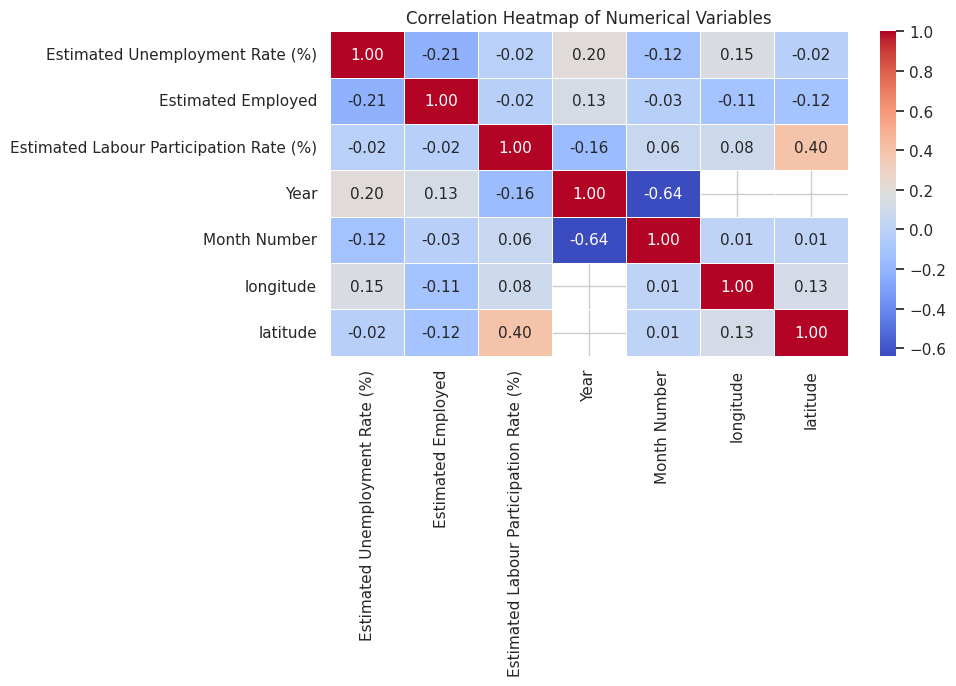

In [ ]:
numeric_data = data.select_dtypes(
    include=["number"]
)

if numeric_data.shape[1] >= 2:

    correlation_matrix = numeric_data.corr()

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap of Numerical Variables")

    plt.tight_layout()
    plt.show()

else:

    print("Not enough numerical columns for a correlation heatmap.")

KEY FINDINGS

In [ ]:
print("\n" + "=" * 65)
print("KEY FINDINGS")
print("=" * 65)

print(
    "\nOverall average unemployment rate:",
    round(data[RATE_COL].mean(), 2),
    "%"
)

print(
    "Highest observed unemployment rate:",
    round(data[RATE_COL].max(), 2),
    "%"
)

print(
    "Lowest observed unemployment rate:",
    round(data[RATE_COL].min(), 2),
    "%"
)


# Highest and lowest regions by dataset
for source in region_summary["Source Dataset"].unique():

    subset = region_summary[
        region_summary["Source Dataset"] == source
    ]

    if not subset.empty:

        highest = subset.loc[
            subset[RATE_COL].idxmax()
        ]

        lowest = subset.loc[
            subset[RATE_COL].idxmin()
        ]

        print(f"\nDataset: {source}")

        print(
            "Highest average unemployment region:",
            highest["Region"],
            "-",
            round(highest[RATE_COL], 2),
            "%"
        )

        print(
            "Lowest average unemployment region:",
            lowest["Region"],
            "-",
            round(lowest[RATE_COL], 2),
            "%"
        )


# COVID comparison findings
for source in covid_summary["Source Dataset"].unique():

    subset = covid_summary[
        covid_summary["Source Dataset"] == source
    ]

    before = subset[
        subset["COVID Period"] == "Before March 2020"
    ]

    during = subset[
        subset["COVID Period"] == "March 2020 Onward"
    ]

    if not before.empty and not during.empty:

        before_rate = before["Average Rate"].iloc[0]
        during_rate = during["Average Rate"].iloc[0]

        difference = during_rate - before_rate

        print(f"\nCOVID-19 comparison for {source}")

        print(
            "Before March 2020:",
            round(before_rate, 2),
            "%"
        )

        print(
            "March 2020 onward:",
            round(during_rate, 2),
            "%"
        )

        print(
            "Difference:",
            round(difference, 2),
            "percentage points"
        )


KEY FINDINGS

Overall average unemployment rate: 11.91 %
Highest observed unemployment rate: 76.74 %
Lowest observed unemployment rate: 0.0 %

Dataset: Unemployment in India.csv
Highest average unemployment region: Tripura - 28.35 %
Lowest average unemployment region: Meghalaya - 4.8 %

Dataset: Unemployment_Rate_upto_11_2020.csv
Highest average unemployment region: Haryana - 27.48 %
Lowest average unemployment region: Meghalaya - 3.87 %

COVID-19 comparison for Unemployment in India.csv
Before March 2020: 9.51 %
March 2020 onward: 17.77 %
Difference: 8.26 percentage points

COVID-19 comparison for Unemployment_Rate_upto_11_2020.csv
Before March 2020: 9.23 %
March 2020 onward: 12.96 %
Difference: 3.73 percentage points


EXPORT CLEANED DATA AND RESULTS

In [ ]:
data.to_csv(
    "cleaned_unemployment_data.csv",
    index=False
)

monthly_trend.to_csv(
    "monthly_unemployment_trend.csv",
    index=False
)

yearly_trend.to_csv(
    "yearly_unemployment_trend.csv",
    index=False
)

region_summary.to_csv(
    "regional_unemployment_summary.csv",
    index=False
)

seasonal_summary.to_csv(
    "seasonal_unemployment_summary.csv",
    index=False
)

covid_summary.to_csv(
    "covid_unemployment_comparison.csv",
    index=False
)

print("\nAnalysis completed successfully!")

print("\nGenerated output files:")
print("1. cleaned_unemployment_data.csv")
print("2. monthly_unemployment_trend.csv")
print("3. yearly_unemployment_trend.csv")
print("4. regional_unemployment_summary.csv")
print("5. seasonal_unemployment_summary.csv")
print("6. covid_unemployment_comparison.csv")


Analysis completed successfully!

Generated output files:
1. cleaned_unemployment_data.csv
2. monthly_unemployment_trend.csv
3. yearly_unemployment_trend.csv
4. regional_unemployment_summary.csv
5. seasonal_unemployment_summary.csv
6. covid_unemployment_comparison.csv
